In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import cooler
import cooltools
from scipy.optimize import curve_fit
from scipy.stats import pearsonr
from matplotlib.lines import Line2D

def func_linear(x, k, m):
    return k*x + m

/exports/igmm/eddie/chr11/elias/anaconda/envs/cool/lib/python3.8/site-packages/requests/__init__.py:102: RequestsDependencyWarning: urllib3 (1.26.8) or chardet (5.1.0)/charset_normalizer (2.0.11) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({})/charset_normalizer ({}) doesn't match a supported "


In [2]:
def generate_virtual_4c(coolers_dict, chrom, viewpoint, view_limits, resolution, regions_dict=None):
    vp_region = (chrom, viewpoint[0], viewpoint[1])
    lim_region = (chrom, view_limits[0], view_limits[1])
    
    tracks = []
    for name, clr in coolers_dict.items():
        bins = clr.bins().fetch(lim_region).copy()
        mat = clr.matrix(balance='weight').fetch(vp_region, lim_region)
        mat = np.nan_to_num(mat)
        profile = np.sum(mat, axis=0)
        bins['value'] = profile
        bins['sample'] = name
        tracks.append(bins)
        
    tracks_df = pd.concat(tracks, ignore_index=True)
    
    tracks_df['log_value'] = np.where(tracks_df['value'] > 0, 
                                      np.log(tracks_df['value']), 
                                      0)
    
    tracks_df['target_region'] = ""
    
    if regions_dict:
        for region_name, (r_start, r_end) in regions_dict.items():
            overlap_mask = (tracks_df['end'] > r_start) & (tracks_df['start'] < r_end)
            tracks_df.loc[overlap_mask, 'target_region'] = region_name
    
    return tracks_df

In [3]:
def calculate_v4c_fold_change(v4c_df, baseline_cond, test_cond, regions_dict, pseudocount=1e-6, column='value'):
    results = []
    for region_name, (start, end) in regions_dict.items():
        region_overlap = v4c_df[(v4c_df['end'] > start) & (v4c_df['start'] < end)]
        sum_baseline = region_overlap[region_overlap['sample'] == baseline_cond][column].sum()
        sum_test = region_overlap[region_overlap['sample'] == test_cond][column].sum()
        fc = (sum_test + pseudocount) / (sum_baseline + pseudocount)
        log2_fc = np.log2(fc)
        
        results.append({
            "Region": region_name,
            "Coordinates": f"{start}-{end}",
            f"baseline_contacts": sum_baseline,
            f"test_contacts": sum_test,
            f"FoldChange": fc,
            "Condition": f"{test_cond}/{baseline_cond}",
        })
        
    return pd.DataFrame(results)

In [4]:
resolution=20000

In [5]:
#Previously published data from:
#https://ftp.ncbi.nlm.nih.gov/geo/series/GSE279nnn/GSE279296/suppl/GSE279296%5FNIPBL%2DFKBP%5Funtreated%5Fmerge%2Drep1%2D2%2Emcool
#https://ftp.ncbi.nlm.nih.gov/geo/series/GSE279nnn/GSE279296/suppl/GSE279296%5FNIPBL%2DFKBP%5FdTAG%2D24h%5Fmerge%5Frep1%2D2%2Emcool
#https://ftp.ncbi.nlm.nih.gov/geo/series/GSE279nnn/GSE279296/suppl/GSE279296%5Funtagged%5Funtreated%5Fmerge%2Drep1%2D2%2Emcool
#https://ftp.ncbi.nlm.nih.gov/geo/series/GSE279nnn/GSE279296/suppl/GSE279296%5FWAPL%2DAID%5Fauxin%5Fmerge%2Drep1%2D2%2Emcool

In [6]:
NIPBL = cooler.Cooler(f'GSE279296_NIPBL-FKBP_untreated_merge-rep1-2.mcool::/resolutions/{resolution}')
NIPBL_deg = cooler.Cooler(f'GSE279296_NIPBL-FKBP_dTAG-24h_merge_rep1-2.mcool::/resolutions/{resolution}')
WAPL = cooler.Cooler(f'GSE279296_untagged_untreated_merge-rep1-2.mcool::/resolutions/{resolution}')
WAPL_deg = cooler.Cooler(f'GSE279296_WAPL-AID_auxin_merge-rep1-2.mcool::/resolutions/{resolution}')

In [7]:
chrom = 'chr11'
sox9_viewpoint = (112_767_750, 112_787_749) #20kb including Sox9
limit_view = (111_435_000, 112_840_000)

target_regions = {
    "1.2Mb": (111567006, 111568450),
    "715kb": (112066534, 112068217),
    "98kb": (112683626, 112685226)
}

coolers = {
    "NIPBL+": NIPBL, 
    "NIPBL-": NIPBL_deg,
    "WAPL+": WAPL,
    "WAPL-": WAPL_deg,
}


v4c_data = generate_virtual_4c(
    coolers_dict = coolers,
    chrom = chrom,
    viewpoint = sox9_viewpoint,
    view_limits = limit_view,
    resolution = resolution,
    regions_dict = target_regions
)

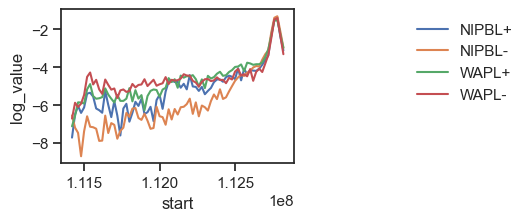

In [8]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(3,2)}, font_scale=1)
g = sns.lineplot(data = v4c_data, x = "start", y = "log_value", 
                  hue = "sample",
                  legend=True)
sns.move_legend(obj=g, loc="upper right", bbox_to_anchor=(2,1), frameon=False, title="")

In [9]:
nipbl_results = calculate_v4c_fold_change(
    v4c_df = v4c_data, 
    baseline_cond = "NIPBL+", 
    test_cond = "NIPBL-", 
    regions_dict = target_regions,
    column="value"
)

wapl_results = calculate_v4c_fold_change(
    v4c_df = v4c_data, 
    baseline_cond = "WAPL+", 
    test_cond = "WAPL-", 
    regions_dict = target_regions,
    column="value"
)

In [10]:
fc_results = pd.concat([nipbl_results, wapl_results])

In [11]:
Sox9_flow = pd.concat([pd.read_table("WAPL_data_FC_Sox9.txt"), pd.read_table("NIPBL_data_FC_Sox9.txt")])
Sox9_flow["Condition"] = np.where(Sox9_flow["cell_line"]=="dTAG-NIPBL", "NIPBL-/NIPBL+", "WAPL-/WAPL+")
Sox9_flow["log_FC"] = np.log(Sox9_flow["FC"])
mergefc = Sox9_flow.rename(columns={"guide": "Region"}).merge(fc_results)
mergefc["log_FoldChange"] = np.log(mergefc["FoldChange"])

([<matplotlib.axis.XTick at 0x7f6a30062a00>,
 [Text(-1.0, 0, '−1.0'), Text(0.0, 0, '0.0'), Text(0.5, 0, '0.5')])

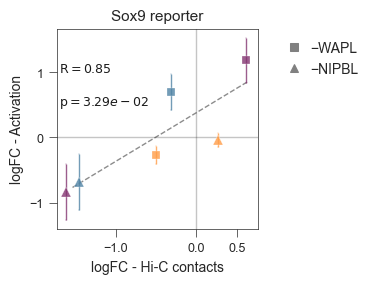

In [12]:
sns.set(
    style="ticks",
    font="Arial",
    rc={
        "axes.linewidth": 0.5,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "xtick.minor.width": 0.5,
        "ytick.minor.width": 0.5,
    },
)

column1 = "log_FoldChange"
column2 = "log_FC"

df = mergefc
meandf = df.groupby(["Condition", "Region"]).mean(numeric_only=True).reset_index()
stddf = df.groupby(["Condition", "Region"]).std(numeric_only=True).reset_index()
plot_df = meandf.copy()
plot_df["yerr"] = stddf[column2]

site_palette = {
    "98kb": "#ff9d47",
    "715kb": "#5083a5",
    "1.2Mb": "#833471",
}


def get_color(region):
    return site_palette.get(str(region), "#000000")


plot_df["Depleted"] = plot_df["Condition"].apply(
    lambda x: "WAPL" if "WAPL" in x else "NIPBL"
)

fig, ax = plt.subplots(figsize=(3.63, 2.75))
ax.set_box_aspect(1)

nipbl = plot_df[plot_df["Depleted"] == "NIPBL"]
wapl = plot_df[plot_df["Depleted"] == "WAPL"]

for _, row in wapl.iterrows():
    ax.errorbar(
        x=row[column1],
        y=row[column2],
        yerr=row["yerr"],
        fmt="s",
        color=get_color(row["Region"]),
        markeredgecolor="white",
        elinewidth=1,
        capsize=1,
        markersize=6,
        markeredgewidth=0.25,
        alpha=0.8,
        zorder=10,
    )

for _, row in nipbl.iterrows():
    ax.errorbar(
        x=row[column1],
        y=row[column2],
        yerr=row["yerr"],
        fmt="^",
        color=get_color(row["Region"]),
        markeredgecolor="white",
        elinewidth=1,
        capsize=1,
        markersize=7,
        markeredgewidth=0.25,
        alpha=0.8,
        zorder=10,
    )

xdata = meandf[column1]
ydata = meandf[column2]
popt, pcov = curve_fit(func_linear, xdata, ydata)
xspace = np.linspace(min(xdata) - min(xdata) / 20, max(xdata) + max(xdata) / 20)
ax.plot(xspace, func_linear(xspace, *popt), "k--", lw=1, zorder=-1, alpha=0.5)

ax.set_ylabel("logFC - Activation", fontsize=10)
ax.set_xlabel("logFC - Hi-C contacts", fontsize=10)
ax.tick_params(labelsize=9)

ax.axhline(0, alpha=0.25, linewidth=1, color="k")
ax.axvline(0, alpha=0.25, linewidth=1, color="k")

prsn = pearsonr(xdata, ydata)
ax.text(-1.7, 1, rf"$\mathrm{{R}}={prsn[0]:.2f}$", fontsize=9, color="k")
ax.text(-1.7, 0.5, rf"$\mathrm{{p}}={prsn[1]:.2e}$", fontsize=9, color="k")
ax.set_title("Sox9 reporter", fontsize=11)


def handle(marker, opacity=1):
    return Line2D(
        [],
        [],
        marker=marker,
        linestyle="none",
        markersize=6,
        markeredgecolor="grey",
        markeredgewidth=0.75,
        markerfacecolor="grey",
    )


handles = [handle("s")] + [handle("^")]
labels = ["\u2212WAPL"] + ["\u2212NIPBL"]

ax.legend(
    handles=handles,
    labels=labels,
    loc="upper left",
    bbox_to_anchor=(1.05, 1),
    frameon=False,
    fontsize=10,
    handletextpad=0.2,
)

plt.subplots_adjust(left=0.18, right=0.78, bottom=0.15, top=0.88)
plt.yticks([-1, 0, 1])
plt.xticks([-1, 0, 0.5])